In [14]:
import numpy as np
import matplotlib.pyplot as plt

from models.multi_layer_perceptron_back_propagation import learning_rate

In [6]:
class Layer:
    def __init__(self):
        return

    def forward_pass(self,x):
        return

    def backward_pass(self, derivative):
        return

    def update(self, derivative):
        return

In [7]:
#Standard relu as a layer, does not need to know params, will use X to map out gradient then apply it to incoming derivatives
class Relu(Layer):
    def __init__(self):
        super().__init__()
        self.x = None
        self.gradient = None

    def forward_pass(self,x):
        self.gradient = np.where(x > 0, 1, 0)
        self.x = x
        return self.x * self.gradient

    def backward_pass(self, derivative):
        return derivative * self.gradient

In [8]:
#Class for leaky ReLU, does not need to know params, will use X to map out gradient then apply it to incoming derivatives
class LeakyRelu(Layer):
    def __init__(self, alpha=0.01):
        super().__init__()
        self.x = None
        self.gradient = None
        self.alpha = alpha
    def forward_pass(self,x):
        self.gradient = np.where(x > 0, 1, self.alpha)
        self.x = x
        return self.x * self.gradient
    def backward_pass(self, derivative):
        return derivative * self.gradient

In [9]:
class Linear(Layer):
    def __init__(self,input_dim,output_dim,learning_rate=0.001,weights=None,biases=None):
        super().__init__()

        if weights is None:
            weights = np.random.uniform(-1,1,size=(output_dim,input_dim))
        if biases is None:
            biases = np.random.uniform(-1,1,size=(output_dim,1))

        self.learning_rate = learning_rate
        self.x = None
        self.weights = weights
        self.biases = biases
        self.input_dim = input_dim
        self.output_dim = output_dim

    def forward_pass(self,x):
        self.x = x
        return self.weights @ x + self.biases

    def backward_pass(self, derivative):
        return self.weights.T @ derivative

    def update(self, derivative):
        weight_gradient = derivative @ self.x.T
        bias_gradient = np.mean(derivative, axis=1,keepdims=True)

        self.weights -= self.learning_rate * weight_gradient
        self.biases -= self.learning_rate * bias_gradient

In [127]:
class Model:
    def __init__(self, layers):
        self.layers = layers

    def forward_pass(self,x):
        inp = x
        for i in self.layers:
            inp = i.forward_pass(inp)
        return inp

    def backward_pass(self, derivative):
        gradient = derivative
        for i in reversed(self.layers):
            temp_gradient = i.backward_pass(gradient)
            i.update(gradient)
            gradient = temp_gradient

    def train(self,x,y,iterations=10000,cutoff = 0.001):
        cost_history = []
        for i in range(iterations):
            prediction = self.forward_pass(x)
            loss = prediction - y
            cost_history.append(np.average(loss**2)/2)
            self.backward_pass(loss)
            if len(cost_history) < 2:
                continue
            if abs((cost_history[-1]-cost_history[-2])/cost_history[-1]) < cutoff:
                break
        return cost_history

    #Input and output is given in as: batch,input/output
    def advanced_train(self, x, y, epoch, batch_size, iterations=100000, cutoff = 0.001):
        cost_history = []
        counter = 0
        for i in range(epoch):
            batches = self.create_batches(x,y,batch_size)
            for batch in batches:
                batch_x = batch[0]
                batch_y = batch[1]
                prediction = self.forward_pass(batch_x)
                loss = prediction - batch_y
                cost_history.append(np.average(loss**2)/2)
                self.backward_pass(loss)
                if len(cost_history) < 2:
                    continue
                if abs((cost_history[-1]-cost_history[-2])/cost_history[-1]) < cutoff:
                    return cost_history
                if counter == iterations:
                    break
                counter += 1
        return cost_history
        return

    def create_batches(self,x,y,batch_size):
        batches = []
        if batch_size > len(x):
            raise Exception("Batch size cannot be larger than the dataset size.")
        indexes = np.arange(len(x))
        np.random.shuffle(indexes)
        x_shuffled = x[indexes]
        y_shuffled = y[indexes]
        for i in range(0,x.shape[0],batch_size):
            batch_x = x_shuffled[i:i+batch_size].T
            batch_y = y_shuffled[i:i+batch_size].T
            batches.append((batch_x,batch_y))
        return batches

In [126]:
#Test create_batches function
x = np.random.uniform(-1,1,size=(100,2))
y = np.random.uniform(-1,1,size=(100,1))
model = Model([])
batches = model.create_batches(x,y,10)
print(f"Number of batches: {len(batches)}")
for i in range(len(batches)):
    batch_x,batch_y = batches[i]
    print(f"Batch {i+1}: {batch_x.shape}, {batch_y.shape}")

Number of batches: 10
Batch 1: (2, 10), (1, 10)
Batch 2: (2, 10), (1, 10)
Batch 3: (2, 10), (1, 10)
Batch 4: (2, 10), (1, 10)
Batch 5: (2, 10), (1, 10)
Batch 6: (2, 10), (1, 10)
Batch 7: (2, 10), (1, 10)
Batch 8: (2, 10), (1, 10)
Batch 9: (2, 10), (1, 10)
Batch 10: (2, 10), (1, 10)


In [55]:
#Funct to plot points
def plot_3d(x1,x2,y):
    fig = plt.figure()
    ax = fig.add_subplot(111, projection="3d")
    ax.scatter(x1,x2,y)
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.set_zlabel("y")
    plt.show()

def plot_x_2d(x,name):
    plt.plot(x,'o',label=name)
    plt.legend()
    plt.show()

def plot_2d(x,y,name):
    plt.plot(x,y,'o',label=name)
    plt.legend()
    plt.show()

def plot_comparison_2d(x1,y1,x2,y2):
    plt.plot(x1,y1,'o',label="1",color="blue")
    plt.plot(x2,y2,'o',label="2",color="orange")
    plt.legend()
    plt.show()

# Function to plot two sets of points
def plot_comparison_3d(x1, x2, y1, x3, x4, y2):
    fig = plt.figure()
    ax = fig.add_subplot(111, projection="3d")
    ax.scatter(x1, x2, y1, color="blue", label="Set 1")
    ax.scatter(x3, x4, y2, color="orange", label="Set 2")
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.set_zlabel("y")
    ax.legend()
    plt.show()

In [45]:
#Horners method for polynomial evaluation
def polynomial(x, coefficients):
    y = 0
    for c in coefficients:
        y = y*x + c
    return y

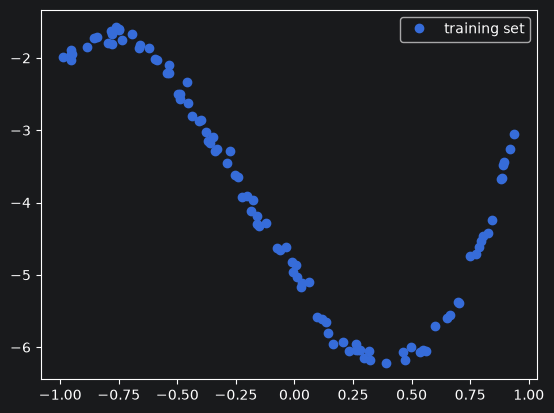

In [92]:
#Linear training data
#Creating inputs:
batch_size = 100
input_size = 1
output_size = 1
scale = 1
deviation = 0.1 #%

x_input = np.random.uniform(-scale,scale,size=[input_size,batch_size])
x_input.sort()
y_output = polynomial(x_input, [5, 3, -5, -5]) + np.random.normal(0, scale * deviation, size=[output_size, batch_size])

plot_2d(x_input.reshape(-1), y_output.reshape(-1), "training set")

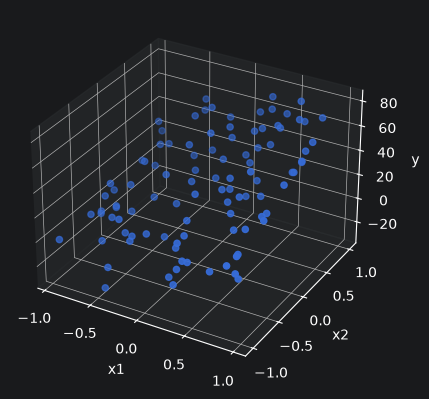

In [27]:
#Training data:
batch_size = 100
input_size = 2
output_size = 1
scale = 1
deviation = 10 #%
w = np.array([20,30])
b = 30
x_input = np.random.uniform(-scale,scale,size=(input_size,100))
y_output = w @ x_input + b + np.random.normal(0,scale*deviation,size=(output_size,100))

#plotting training data
plot_3d(*x_input,y_output)

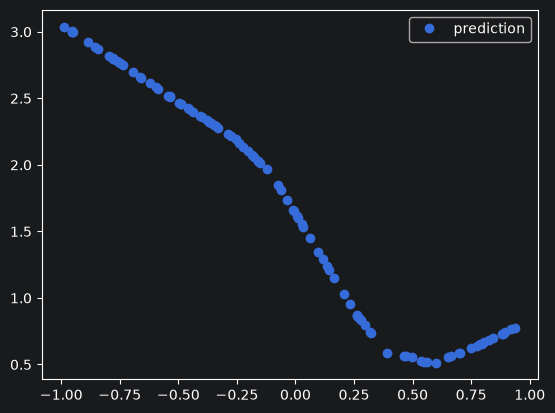

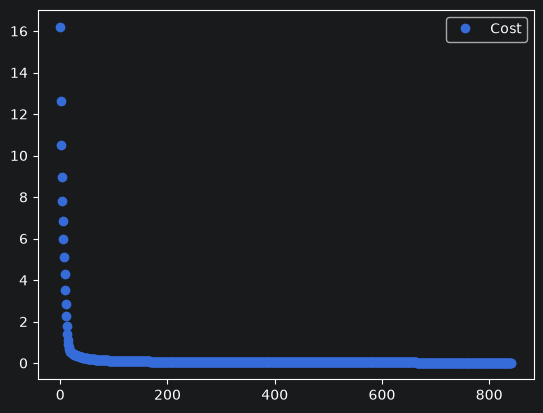

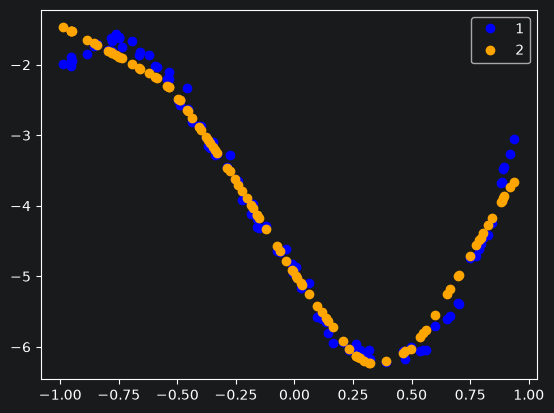

In [113]:

learning_rate = 0.0001
model = Model([
    Linear(input_dim=1,output_dim=10,learning_rate=learning_rate),
    Relu(),
    Linear(input_dim=10,output_dim=10,learning_rate=learning_rate),
    Relu(),
    Linear(input_dim=10,output_dim=10,learning_rate=learning_rate),
    Relu(),
    Linear(input_dim=10,output_dim=1,learning_rate=learning_rate)
])
#prediction graph:
y_hat = model.forward_pass(x_input)
plot_2d(x_input.reshape(-1),y_hat.reshape(-1),"prediction")

cost_history = model.train(x_input,y_output,iterations=100000,cutoff=0.0008)

#Trained graph:
y_hat = model.forward_pass(x_input)
plot_x_2d(cost_history,"Cost")
plot_comparison_2d(x_input.reshape(-1), y_output.reshape(-1), x_input.reshape(-1), y_hat.reshape(-1))